# Collaborative Filtering — Baseline Analysis & Popularity Bias
**Dataset:** MovieLens 1M (local)  
**Goal:** Implement CF algorithms from scratch, prove popularity bias exists in each, and select a principled baseline.

---
### Roadmap
1. Data Loading & EDA
2. Popularity Bias: Metrics
3. Naive Baselines: Global Mean, Bias Model (μ + b_u + b_i)
4. CF Algorithms: User-User KNN, Item-Item KNN, SVD
5. Comparison & Baseline Selection

## 1. Data Loading & EDA

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid', palette='muted')
np.random.seed(42)


DATA_PATH = '../data/ml-1m/ratings.dat'   # see README for download instructions
ITEM_PATH = '../data/ml-1m/movies.dat'

ratings = pd.read_csv(DATA_PATH, sep='::', engine='python',
                      names=['userId', 'itemId', 'rating', 'timestamp'])

movies = pd.read_csv(ITEM_PATH, sep='::', engine='python', encoding='latin-1',
                     names=['itemId', 'title', 'genres'])

n_users   = ratings.userId.nunique()
n_items   = ratings.itemId.nunique()
n_ratings = len(ratings)
sparsity  = 1 - n_ratings / (n_users * n_items)

print(f'Users    : {n_users}')
print(f'Items    : {n_items}')
print(f'Ratings  : {n_ratings}')
print(f'Sparsity : {sparsity:.2%}')
ratings.head()

Users    : 6040
Items    : 3706
Ratings  : 1000209
Sparsity : 95.53%


,userId,itemId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [2]:
# ── Build 0-based integer indices for matrix operations ───────────────────────
user_ids  = sorted(ratings.userId.unique())
item_ids  = sorted(ratings.itemId.unique())
user2idx  = {u: i  for i, u  in enumerate(user_ids)}
item2idx  = {it: i for i, it in enumerate(item_ids)}
idx2item  = {i: it for it, i in item2idx.items()}

ratings['u'] = ratings.userId.map(user2idx)
ratings['i'] = ratings.itemId.map(item2idx)

# Item popularity = number of ratings per item
item_popularity = ratings.groupby('itemId').size()  # Series: itemId -> count

print('Index maps built.')

Index maps built.


In [3]:
# ── Popularity Buckets ─────────────────────────────────────────────
pop_df = item_popularity.reset_index()
pop_df.columns = ['itemId', 'popularity']

pop_df['bucket'] = pd.qcut(
    pop_df['popularity'],
    q=5,
    labels=['Niche', 'Low', 'Medium', 'High', 'Blockbuster']
)

item_bucket = dict(zip(pop_df['itemId'], pop_df['bucket']))

In [4]:
def temporal_split(df, test_ratio=0.2):
    train_list = []
    test_list = []

    for uid, group in df.groupby('userId'):
        group = group.sort_values('timestamp')
        n = len(group)
        split = int(n * (1 - test_ratio))

        train_list.append(group.iloc[:split])
        test_list.append(group.iloc[split:])

    train_df = pd.concat(train_list).reset_index(drop=True)
    test_df  = pd.concat(test_list).reset_index(drop=True)

    return train_df, test_df

In [5]:
train_df, test_df = temporal_split(ratings, test_ratio=0.2)

print(f'Train: {len(train_df)} | Test: {len(test_df)}')

Train: 797758 | Test: 202451


In [6]:
# ── Build index mappings ─────────────────────────────────────────────────────
user_ids  = sorted(ratings.userId.unique())
item_ids  = sorted(ratings.itemId.unique())

user2idx  = {u: i for i, u in enumerate(user_ids)}
item2idx  = {it: i for i, it in enumerate(item_ids)}

idx2item  = {i: it for it, i in item2idx.items()}

n_users   = len(user_ids)
n_items   = len(item_ids)

print(f'Users: {n_users}, Items: {n_items}')

Users: 6040, Items: 3706


In [7]:
# ── Map user/item IDs to indices (AFTER temporal split) ──────────────────────
train_df['u'] = train_df.userId.map(user2idx)
train_df['i'] = train_df.itemId.map(item2idx)

test_df['u'] = test_df.userId.map(user2idx)
test_df['i'] = test_df.itemId.map(item2idx)

# ── Safety check: ensure no missing mappings ─────────────────────────────────
print("Missing in train:\n", train_df[['u','i']].isna().sum())
print("Missing in test:\n", test_df[['u','i']].isna().sum())

# ── Convert to integer (important for indexing) ──────────────────────────────
train_df['u'] = train_df['u'].astype(int)
train_df['i'] = train_df['i'].astype(int)

test_df['u'] = test_df['u'].astype(int)
test_df['i'] = test_df['i'].astype(int)

# ── Build Rating Matrix R (TRAIN ONLY) ───────────────────────────────────────
# R[u, i] = rating if user u rated item i, else 0

R = np.zeros((n_users, n_items), dtype=np.float32)

# Vectorized (fast) version
R[train_df['u'], train_df['i']] = train_df['rating']

print(f'Rating matrix shape: {R.shape}')

Missing in train:
 u    0
i    0
dtype: int64
Missing in test:
 u    0
i    0
dtype: int64
Rating matrix shape: (6040, 3706)


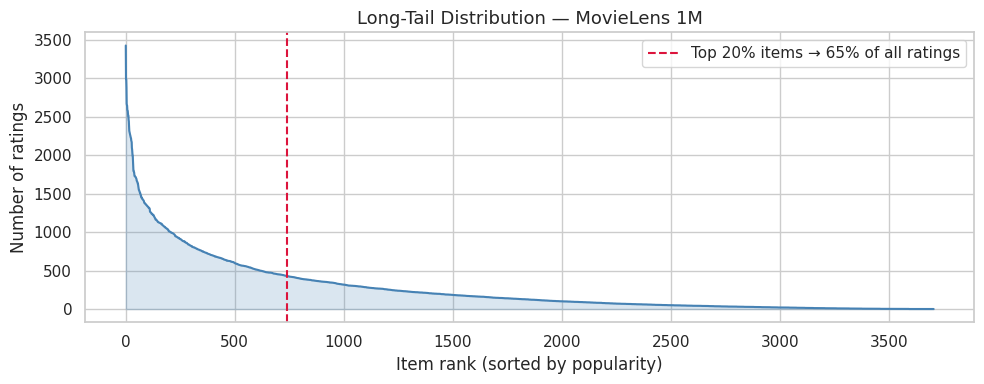

Top 20% items account for 65.2% of all ratings — severe long tail.


In [8]:
# ── Long-tail distribution plot ───────────────────────────────────────────────
sorted_pop    = item_popularity.sort_values(ascending=False).values
top20_share   = sorted_pop[:int(n_items * 0.2)].sum() / sorted_pop.sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sorted_pop, color='steelblue', linewidth=1.5)
ax.fill_between(range(len(sorted_pop)), sorted_pop, alpha=0.2, color='steelblue')
ax.axvline(int(n_items * 0.2), color='crimson', linestyle='--',
           label=f'Top 20% items → {top20_share:.0%} of all ratings')
ax.set_xlabel('Item rank (sorted by popularity)')
ax.set_ylabel('Number of ratings')
ax.set_title('Long-Tail Distribution — MovieLens 1M', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

print(f'Top 20% items account for {top20_share:.1%} of all ratings — severe long tail.')

---
## 2. Popularity Bias — Metrics

**Popularity bias** = the tendency to over-recommend already-popular items, ignoring the long tail.

| Metric | What it measures | Better direction |
|---|---|---|
| **ARP** (Avg Recommendation Popularity) | Mean rating-count of recommended items | Lower |
| **Coverage** | % of catalogue ever recommended to any user | Higher |

In [9]:
TOP_N = 10   # recommendations per user

def rmse(actual, predicted):
    return np.sqrt(np.mean((np.array(actual) - np.array(predicted)) ** 2))

def mae(actual, predicted):
    return np.mean(np.abs(np.array(actual) - np.array(predicted)))

def eval_rating_preds(test_df, pred_fn, label):
    """Score a prediction function on the test set."""
    preds, actuals = [], []
    for row in test_df.itertuples():
        p = pred_fn(row.u, row.i)
        preds.append(float(np.clip(p, 1, 5)))
        actuals.append(row.rating)
    r = rmse(actuals, preds)
    m = mae(actuals, preds)
    print(f'  [{label}]  RMSE={r:.4f}  MAE={m:.4f}')
    return r, m

def avg_rec_popularity(top_n_dict, item_popularity):
    """Mean popularity score of all recommended items."""
    vals = [item_popularity.get(iid, 0)
            for recs in top_n_dict.values() for iid in recs]
    return float(np.mean(vals))

def catalogue_coverage(top_n_dict, n_items):
    return len({iid for recs in top_n_dict.values() for iid in recs}) / n_items

def score_bias(top_n_dict, item_popularity, n_items, label):
    arp = avg_rec_popularity(top_n_dict, item_popularity)
    cov = catalogue_coverage(top_n_dict, n_items)
    print(f'  [{label}]  ARP={arp:.1f}  Coverage={cov:.2%}')
    return arp, cov

results = []
print('Helpers defined.')

def rmse_by_bucket(test_df, pred_fn, item_bucket):
    bucket_preds = defaultdict(list)
    bucket_actuals = defaultdict(list)

    for row in test_df.itertuples():
        bucket = item_bucket.get(row.itemId, 'Unknown')

        pred = np.clip(pred_fn(row.u, row.i), 1, 5)

        bucket_preds[bucket].append(pred)
        bucket_actuals[bucket].append(row.rating)

    bucket_rmse = {}
    for b in bucket_preds:
        bucket_rmse[b] = rmse(bucket_actuals[b], bucket_preds[b])

    return bucket_rmse

Helpers defined.


---
## 3. Naive Baselines

No personalisation at all. These represent the absolute worst-case for popularity bias — they recommend the same popular movies to every user.

In [11]:
# Mean rating per item (for prediction)
item_mean = train_df.groupby('i')['rating'].mean().to_dict()

def predict_popularity(u, i):
    return item_mean.get(i, mu)

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# 3a. POPULARITY RANKING
# Recommend the most-rated items to every user.
# Maximum possible popularity bias — serves as the ceiling.
# ─────────────────────────────────────────────────────────────────────────────
top_pop_items = item_popularity.nlargest(TOP_N).index.tolist()   # original itemIds
pop_top_n     = {uid: top_pop_items for uid in user_ids}

print('Popularity Ranking')

arp, cov = score_bias(pop_top_n, item_popularity, n_items, 'Popularity Ranking')
r, m = eval_rating_preds(test_df, predict_popularity, 'Popularity Ranking')

bucket_scores = rmse_by_bucket(test_df, predict_popularity, item_bucket)
print("\nRMSE by Popularity Bucket (Popularity Ranking):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")

results.append(dict(
    model='Popularity Ranking',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))
print('\nTop 10 most popular movies:')
print(movies[movies.itemId.isin(top_pop_items)][['itemId','title']].to_string(index=False))

Popularity Ranking
  [Popularity Ranking]  ARP=2801.7  Coverage=0.27%
  [Popularity Ranking]  RMSE=0.9895  MAE=0.7871

RMSE by Popularity Bucket (Popularity Ranking):
Niche: 1.2016
Low: 1.0623
Medium: 1.0395
High: 0.9900
Blockbuster: 0.9679

Top 10 most popular movies:
 itemId                                                 title
    260             Star Wars: Episode IV - A New Hope (1977)
    480                                  Jurassic Park (1993)
    589                     Terminator 2: Judgment Day (1991)
    593                      Silence of the Lambs, The (1991)
   1196 Star Wars: Episode V - The Empire Strikes Back (1980)
   1210     Star Wars: Episode VI - Return of the Jedi (1983)
   1270                             Back to the Future (1985)
   2028                            Saving Private Ryan (1998)
   2571                                    Matrix, The (1999)
   2858                                American Beauty (1999)


In [13]:
# ─────────────────────────────────────────────────────────────────────────────
# 3b. GLOBAL MEAN  r̂(u,i) = μ
# Predict the same global average for every pair.
# For top-N: every item has the same score → popular items win by tiebreak.
# ─────────────────────────────────────────────────────────────────────────────
mu = float(train_df.rating.mean())
print(f'Global mean rating: {mu:.4f}\n')

print('Global Mean')
r, m = eval_rating_preds(test_df, lambda u, i: mu, 'Global Mean')
bucket_scores = rmse_by_bucket(test_df, lambda u, i: mu, item_bucket)
print("\nRMSE by Popularity Bucket (Global Mean):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")


# All items tie → use popularity order as tiebreaker (most biased interpretation)
global_top_n = {uid: top_pop_items for uid in user_ids}
arp, cov     = score_bias(global_top_n, item_popularity, n_items, 'Global Mean')
results.append(dict(
    model='Global Mean',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))

Global mean rating: 3.6170

Global Mean
  [Global Mean]  RMSE=1.1466  MAE=0.9440

RMSE by Popularity Bucket (Global Mean):
Niche: 1.3629
Low: 1.3538
Medium: 1.3351
High: 1.1746
Blockbuster: 1.0646
  [Global Mean]  ARP=2801.7  Coverage=0.27%


In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# 3c. BIAS MODEL  r̂(u,i) = μ + b_u + b_i
#
# Accounts for user & item rating tendencies.
# Standard Netflix Prize baseline — the canonical CF starting point.
#
# Why it still has popularity bias:
#   Popular items have many ratings → their b_i is estimated accurately and
#   tends to be high → they consistently float to the top of every user's list.
# ─────────────────────────────────────────────────────────────────────────────

def fit_bias(train_df, mu, n_users, n_items, lam_u=15, lam_i=10, n_iter=10):
    """ALS estimation of user and item biases."""
    b_u = np.zeros(n_users, dtype=np.float32)
    b_i = np.zeros(n_items, dtype=np.float32)
    train_arr = train_df[['u', 'i', 'rating']].values
    for _ in range(n_iter):
        # Update b_i
        for grp_i, grp in train_df.groupby('i'):
            resid    = grp.rating.values - mu - b_u[grp.u.values]
            b_i[grp_i] = resid.sum() / (lam_i + len(grp))
        # Update b_u
        for grp_u, grp in train_df.groupby('u'):
            resid    = grp.rating.values - mu - b_i[grp.i.values]
            b_u[grp_u] = resid.sum() / (lam_u + len(grp))
    return b_u, b_i

print('Fitting Bias Model:',end="")
b_u_bias, b_i_bias = fit_bias(train_df, mu, n_users, n_items)

def predict_bias(u, i):
    return mu + b_u_bias[u] + b_i_bias[i]

print('Bias Model (μ + bᵤ + bᵢ)')
r, m = eval_rating_preds(test_df, predict_bias, 'Bias Model')
bucket_scores = rmse_by_bucket(test_df, predict_bias, item_bucket)

print("\nRMSE by Popularity Bucket (Bias Model):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")

# Top-N per user
bias_top_n = {}
for u_idx, uid in enumerate(user_ids):
    scores       = mu + b_u_bias[u_idx] + b_i_bias          # (n_items,)
    rated_mask   = R[u_idx] > 0
    scores[rated_mask] = -np.inf
    top_idx      = np.argsort(scores)[-TOP_N:][::-1]
    bias_top_n[uid] = [idx2item[i] for i in top_idx]
    scores[rated_mask] = 0   # restore

arp, cov = score_bias(bias_top_n, item_popularity, n_items, 'Bias Model')
results.append(dict(
    model='Bias Model (μ+bᵤ+bᵢ)',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))

Fitting Bias Model:Bias Model (μ + bᵤ + bᵢ)
  [Bias Model]  RMSE=0.9222  MAE=0.7261

RMSE by Popularity Bucket (Bias Model):
Niche: 1.1266
Low: 0.9971
Medium: 0.9556
High: 0.9117
Blockbuster: 0.9092
  [Bias Model]  ARP=1037.6  Coverage=1.67%


**Observation:** Naive baselines have very high ARP and near-zero coverage — they recommend the same small set of blockbusters to everyone.

---
## 4. CF Algorithms

Personalised models. These *should* reduce popularity bias. We will prove they still have residual bias.

In [15]:
# ── Shared utility: cosine similarity matrix ──────────────────────────────────
def cosine_sim(M):
    """
    Row-wise cosine similarity for matrix M  (n × k).
    Returns (n × n) similarity matrix.
    """
    norms       = np.linalg.norm(M, axis=1, keepdims=True)
    norms[norms == 0] = 1e-10
    M_norm      = M / norms
    return (M_norm @ M_norm.T).astype(np.float32)

print('Cosine similarity helper defined.')

Cosine similarity helper defined.


In [16]:
# ─────────────────────────────────────────────────────────────────────────────
# 4a. USER-USER KNN  (k = 40, cosine similarity)
#
# Prediction:
#   r̂(u,i) = ū + Σ sim(u,v)·(r(v,i) − v̄) / Σ|sim(u,v)|
#   over k most similar users v who have rated item i
#
# Popularity bias source:
#   Popular items appear in many users' histories → they dominate neighbourhood
#   rating pools → get recommended regardless of active user's actual preferences.
# ─────────────────────────────────────────────────────────────────────────────
K_USERS = 40

print('Computing user-user similarity matrix')
UU_sim = cosine_sim(R)
np.fill_diagonal(UU_sim, 0)
print(f'Shape: {UU_sim.shape}')

# Per-user mean rating (only over rated items)
rated_counts = (R > 0).sum(axis=1)                        # (n_users,)
user_mean    = np.where(rated_counts > 0,
                        R.sum(axis=1) / np.maximum(rated_counts, 1),
                        mu)

Computing user-user similarity matrix
Shape: (6040, 6040)


In [17]:
def predict_uu(u, i, k=K_USERS):
    sims        = UU_sim[u].copy()
    has_rated_i = R[:, i] > 0
    sims       *= has_rated_i                              # zero out non-raters
    top_k       = np.argsort(sims)[-k:]
    sim_k       = sims[top_k]
    rat_k       = R[top_k, i]
    valid       = (sim_k > 0) & (rat_k > 0)
    if valid.sum() == 0:
        return user_mean[u]
    denom = np.abs(sim_k[valid]).sum()
    if denom < 1e-10:
        return user_mean[u]
    numer = (sim_k[valid] * (rat_k[valid] - user_mean[top_k[valid]])).sum()
    return float(user_mean[u] + numer / denom)

print(f' User-User KNN (k={K_USERS})')
r, m = eval_rating_preds(test_df, predict_uu, f'User-User KNN k={K_USERS}')
bucket_scores = rmse_by_bucket(test_df, predict_uu, item_bucket)
print("\nRMSE by Popularity Bucket (User-User KNN):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")


 User-User KNN (k=40)
  [User-User KNN k=40]  RMSE=0.9216  MAE=0.7181

RMSE by Popularity Bucket (User-User KNN):
Niche: 1.1058
Low: 0.9897
Medium: 0.9533
High: 0.9119
Blockbuster: 0.9095


In [18]:
# Top-N for User-User KNN  (vectorised over items)
print('Generating User-User KNN top-N')

R_centred = R.copy()
for u_idx in range(n_users):
    mask = R[u_idx] > 0
    R_centred[u_idx, mask] -= user_mean[u_idx]

uu_top_n = {}
for u_idx in range(n_users):
    sims    = UU_sim[u_idx]
    top_k   = np.argsort(sims)[-K_USERS:]
    w       = sims[top_k]
    scores  = user_mean[u_idx] + (w @ R_centred[top_k]) / (np.abs(w).sum() + 1e-10)
    scores[R[u_idx] > 0] = -np.inf
    top_idx = np.argsort(scores)[-TOP_N:][::-1]
    uu_top_n[user_ids[u_idx]] = [idx2item[i] for i in top_idx]

arp, cov = score_bias(uu_top_n, item_popularity, n_items, f'User-User KNN k={K_USERS}')
results.append(dict(
    model=f'User-User KNN (k={K_USERS})',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))

Generating User-User KNN top-N
  [User-User KNN k=40]  ARP=1788.0  Coverage=19.54%


In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# 4b. ITEM-ITEM KNN  (k = 40, cosine similarity)
#
# Prediction:
#   r̂(u,i) = Σ sim(i,j)·r(u,j) / Σ|sim(i,j)|
#   over k most similar items j that user u has rated
#
# Popularity bias source:
#   Popular items are rated by many users → dense similarity vectors
#   → appear as top neighbours of many other items → get over-recommended.
# ─────────────────────────────────────────────────────────────────────────────
K_ITEMS = 40

print('Computing item-item similarity matrix')
II_sim = cosine_sim(R.T)
np.fill_diagonal(II_sim, 0)
print(f' Shape: {II_sim.shape}')

Computing item-item similarity matrix
 Shape: (3706, 3706)


In [20]:
def predict_ii(u, i, k=K_ITEMS):
    sims    = II_sim[i].copy()
    rated_u = R[u] > 0
    sims   *= rated_u
    top_k   = np.argsort(sims)[-k:]
    sim_k   = sims[top_k]
    rat_k   = R[u, top_k]
    valid   = (sim_k > 0) & (rat_k > 0)
    if valid.sum() == 0:
        return mu
    denom = np.abs(sim_k[valid]).sum()
    if denom < 1e-10:
        return mu
    return float((sim_k[valid] * rat_k[valid]).sum() / denom)

print(f' Item-Item KNN (k={K_ITEMS})')
r, m = eval_rating_preds(test_df, predict_ii, f'Item-Item KNN k={K_ITEMS}')
bucket_scores = rmse_by_bucket(test_df, predict_ii, item_bucket)

print("\nRMSE by Popularity Bucket (Item-Item KNN):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")

 Item-Item KNN (k=40)
  [Item-Item KNN k=40]  RMSE=1.0126  MAE=0.7867

RMSE by Popularity Bucket (Item-Item KNN):
Niche: 1.1537
Low: 1.1160
Medium: 1.1232
High: 1.0336
Blockbuster: 0.9656


In [22]:
# Top-N for Item-Item KNN
print('Generating Item-Item KNN top-N')
ii_top_n = {}
for u_idx in range(n_users):
    rated_idx = np.where(R[u_idx] > 0)[0]
    if len(rated_idx) == 0:
        ii_top_n[user_ids[u_idx]] = top_pop_items[:TOP_N]
        continue
    # For each item: weighted sum of similarities to rated items
    sim_block = II_sim[:, rated_idx]               # (n_items, |rated|)
    rat_block = R[u_idx, rated_idx]                # (|rated|,)
    # Keep only top-K_ITEMS neighbours per candidate item
    for col_j in range(sim_block.shape[1]):
        col = sim_block[:, col_j]
        threshold = np.partition(col, -K_ITEMS)[-K_ITEMS] if len(col) > K_ITEMS else 0
        sim_block[col < threshold, col_j] = 0
    numer  = sim_block @ rat_block
    denom  = np.abs(sim_block).sum(axis=1) + 1e-10
    scores = numer / denom
    scores[R[u_idx] > 0] = -np.inf
    top_idx = np.argsort(scores)[-TOP_N:][::-1]
    ii_top_n[user_ids[u_idx]] = [idx2item[i] for i in top_idx]

arp, cov = score_bias(ii_top_n, item_popularity, n_items, f'Item-Item KNN k={K_ITEMS}')
results.append(dict(
    model=f'Item-Item KNN (k={K_ITEMS})',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))
print('Done.')

Generating Item-Item KNN top-N
  [Item-Item KNN k=40]  ARP=636.5  Coverage=88.07%
Done.


In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# 4c. SVD — Matrix Factorization  (SGD training)
#
# R ≈ μ + b_u + b_i + P · Qᵀ
#   P ∈ ℝ^(n_users × k),  Q ∈ ℝ^(n_items × k)
#
# Popularity bias source:
#   Popular items have many training examples → their q_i vectors are better
#   optimised and have lower variance → they rank higher and dominate top-N.
# ─────────────────────────────────────────────────────────────────────────────

N_FACTORS = 50
N_EPOCHS  = 20
LR        = 0.005
REG       = 0.02

def fit_svd(train_df, n_users, n_items, mu,
            n_factors=50, n_epochs=20, lr=0.005, reg=0.02):
    P  = np.random.normal(0, 0.1, (n_users, n_factors)).astype(np.float32)
    Q  = np.random.normal(0, 0.1, (n_items, n_factors)).astype(np.float32)
    bu = np.zeros(n_users, dtype=np.float32)
    bi = np.zeros(n_items, dtype=np.float32)
    rows = train_df[['u', 'i', 'rating']].values.astype(np.float32)
    for epoch in range(n_epochs):
        np.random.shuffle(rows)
        for row in rows:
            u, i, r = int(row[0]), int(row[1]), row[2]
            err   = r - (mu + bu[u] + bi[i] + P[u] @ Q[i])
            bu[u] += lr * (err - reg * bu[u])
            bi[i] += lr * (err - reg * bi[i])
            P[u]  += lr * (err * Q[i] - reg * P[u])
            Q[i]  += lr * (err * P[u] - reg * Q[i])
        if (epoch + 1) % 5 == 0:
            us = rows[:, 0].astype(int)
            is_ = rows[:, 1].astype(int)
            preds_tr = mu + bu[us] + bi[is_] + np.sum(P[us] * Q[is_], axis=1)
            tr_rmse  = np.sqrt(np.mean((rows[:, 2] - np.clip(preds_tr, 1, 5))**2))
            print(f'  Epoch {epoch+1:2d}/{n_epochs}  train RMSE={tr_rmse:.4f}')
    return P, Q, bu, bi

print(f'Training SVD (factors={N_FACTORS}, epochs={N_EPOCHS})...')
P, Q, bu_svd, bi_svd = fit_svd(train_df, n_users, n_items, mu,
                                n_factors=N_FACTORS, n_epochs=N_EPOCHS,
                                lr=LR, reg=REG)
print('Training complete.')

Training SVD (factors=50, epochs=20)...
  Epoch  5/20  train RMSE=0.8854
  Epoch 10/20  train RMSE=0.8409
  Epoch 15/20  train RMSE=0.7827
  Epoch 20/20  train RMSE=0.7317
Training complete.


In [24]:
def predict_svd(u, i):
    return float(mu + bu_svd[u] + bi_svd[i] + P[u] @ Q[i])

print(f'SVD MF (k={N_FACTORS})')
r, m = eval_rating_preds(test_df, predict_svd, f'SVD MF k={N_FACTORS}')
# ── RMSE by Popularity Bucket (SVD) ─────────────────────────────
bucket_scores = rmse_by_bucket(test_df, predict_svd, item_bucket)

print("\nRMSE by Popularity Bucket (SVD):")
for k in ['Niche', 'Low', 'Medium', 'High', 'Blockbuster']:
    print(f"{k}: {bucket_scores.get(k, 0):.4f}")

# Top-N: full score matrix in one shot
scores_svd          = mu + bu_svd[:, None] + bi_svd[None, :] + P @ Q.T  # (n_users, n_items)
scores_svd[R > 0]   = -np.inf

svd_top_n = {}
for u_idx in range(n_users):
    top_idx = np.argsort(scores_svd[u_idx])[-TOP_N:][::-1]
    svd_top_n[user_ids[u_idx]] = [idx2item[i] for i in top_idx]

arp, cov = score_bias(svd_top_n, item_popularity, n_items, f'SVD MF k={N_FACTORS}')
results.append(dict(
    model=f'SVD MF (k={N_FACTORS})',
    rmse=r,
    mae=m,
    arp=arp,
    coverage=cov,
    niche=bucket_scores.get('Niche', np.nan),
    low=bucket_scores.get('Low', np.nan),
    medium=bucket_scores.get('Medium', np.nan),
    high=bucket_scores.get('High', np.nan),
    blockbuster=bucket_scores.get('Blockbuster', np.nan)
))

SVD MF (k=50)
  [SVD MF k=50]  RMSE=0.8931  MAE=0.6996

RMSE by Popularity Bucket (SVD):
Niche: 1.1091
Low: 0.9693
Medium: 0.9292
High: 0.8872
Blockbuster: 0.8769
  [SVD MF k=50]  ARP=1100.9  Coverage=18.86%


---
## 5. Comparison & Baseline Selection

In [25]:
res_df = pd.DataFrame(results)

disp = res_df.copy()

# Format metrics
disp['rmse'] = disp['rmse'].map(lambda x: f'{x:.4f}')
disp['mae'] = disp['mae'].map(lambda x: f'{x:.4f}')
disp['arp'] = disp['arp'].map(lambda x: f'{x:.1f}')
disp['coverage'] = disp['coverage'].map(lambda x: f'{x:.2%}')

# Format bucket RMSEs
for col in ['niche', 'low', 'medium', 'high', 'blockbuster']:
    disp[col] = disp[col].map(lambda x: f'{x:.4f}')

disp.columns = [
    'Model', 'RMSE', 'MAE',
    'ARP ↓', 'Coverage ↑',
    'Niche RMSE', 'Low RMSE', 'Medium RMSE',
    'High RMSE', 'Blockbuster RMSE'
]

print("\nFinal Results (with Popularity Buckets):\n")
print(disp.to_string(index=False))


Final Results (with Popularity Buckets):

               Model   RMSE    MAE  ARP ↓ Coverage ↑ Niche RMSE Low RMSE Medium RMSE High RMSE Blockbuster RMSE
  Popularity Ranking 0.9895 0.7871 2801.7      0.27%     1.2016   1.0623      1.0395    0.9900           0.9679
         Global Mean 1.1466 0.9440 2801.7      0.27%     1.3629   1.3538      1.3351    1.1746           1.0646
Bias Model (μ+bᵤ+bᵢ) 0.9222 0.7261 1037.6      1.67%     1.1266   0.9971      0.9556    0.9117           0.9092
User-User KNN (k=40) 0.9216 0.7181 1788.0     19.54%     1.1058   0.9897      0.9533    0.9119           0.9095
Item-Item KNN (k=40) 1.0126 0.7867  636.5     88.07%     1.1537   1.1160      1.1232    1.0336           0.9656
       SVD MF (k=50) 0.8931 0.6996 1100.9     18.86%     1.1091   0.9693      0.9292    0.8872           0.8769


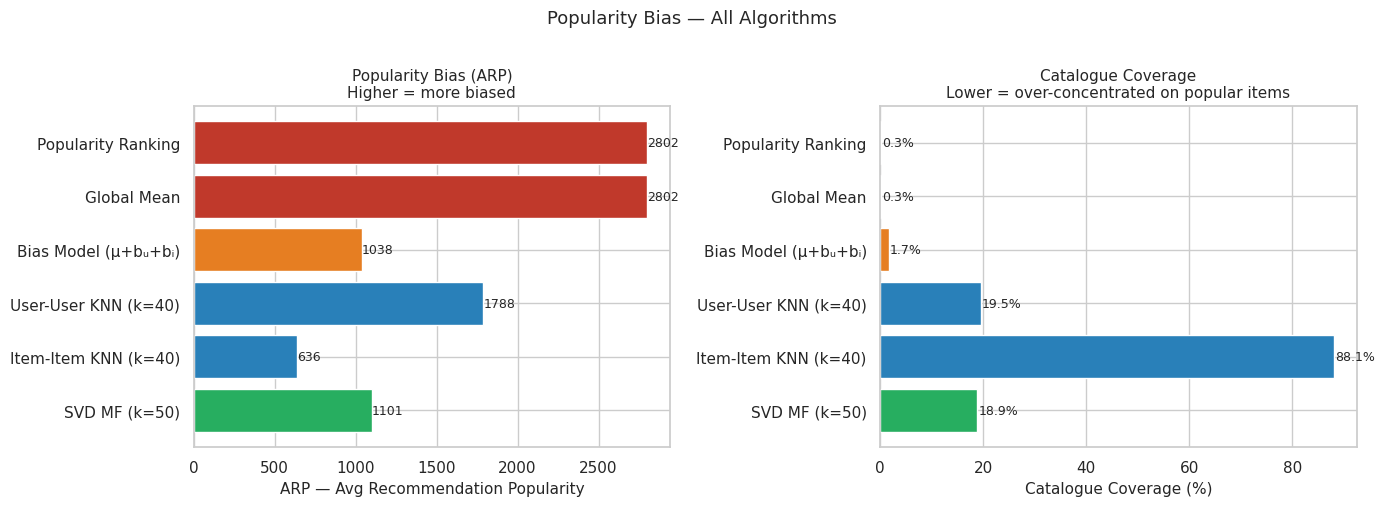

In [26]:
# Plot 1: ARP and Coverage bar charts
palette = ['#c0392b', '#c0392b', '#e67e22', '#2980b9', '#2980b9', '#27ae60']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bars = ax.barh(res_df['model'], res_df['arp'], color=palette[:len(res_df)])
ax.set_xlabel('ARP — Avg Recommendation Popularity', fontsize=11)
ax.set_title('Popularity Bias (ARP)\nHigher = more biased', fontsize=11)
ax.invert_yaxis()
for b, v in zip(bars, res_df['arp']):
    ax.text(v + 0.5, b.get_y() + b.get_height()/2, f'{v:.0f}', va='center', fontsize=9)

ax2 = axes[1]
bars2 = ax2.barh(res_df['model'], res_df['coverage'] * 100, color=palette[:len(res_df)])
ax2.set_xlabel('Catalogue Coverage (%)', fontsize=11)
ax2.set_title('Catalogue Coverage\nLower = over-concentrated on popular items', fontsize=11)
ax2.invert_yaxis()
for b, v in zip(bars2, res_df['coverage']):
    ax2.text(v * 100 + 0.2, b.get_y() + b.get_height()/2, f'{v*100:.1f}%', va='center', fontsize=9)

plt.suptitle('Popularity Bias — All Algorithms', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('bias_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

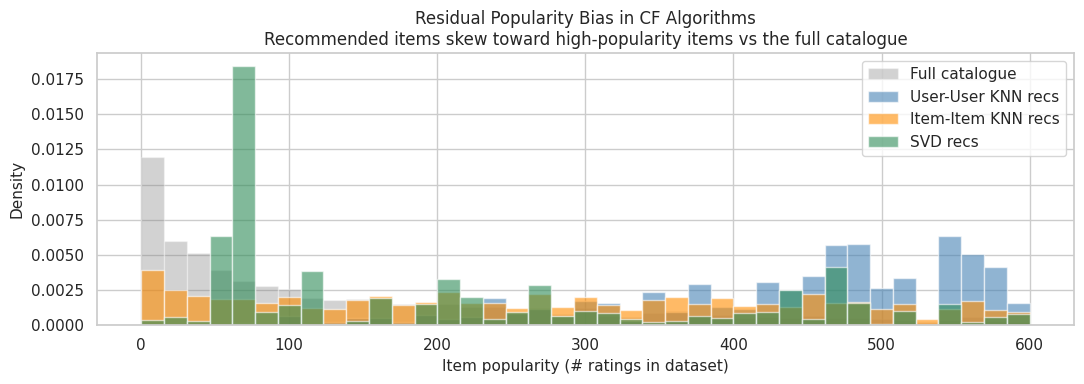

In [27]:
# Plot 2: Proof of RESIDUAL bias in CF models
# recommendations still skew toward popular items vs the full catalogue

def rec_pop_vals(top_n_dict, item_popularity):
    return [item_popularity.get(iid, 0)
            for recs in top_n_dict.values() for iid in recs]

all_pop  = item_popularity.values.tolist()
uu_pop   = rec_pop_vals(uu_top_n,  item_popularity)
ii_pop   = rec_pop_vals(ii_top_n,  item_popularity)
svd_pop  = rec_pop_vals(svd_top_n, item_popularity)

fig, ax = plt.subplots(figsize=(11, 4))
bins = np.linspace(0, 600, 40)
ax.hist(all_pop,  bins=bins, alpha=0.35, label='Full catalogue',       color='grey',        density=True)
ax.hist(uu_pop,   bins=bins, alpha=0.60, label='User-User KNN recs',    color='steelblue',   density=True)
ax.hist(ii_pop,   bins=bins, alpha=0.60, label='Item-Item KNN recs',    color='darkorange',  density=True)
ax.hist(svd_pop,  bins=bins, alpha=0.60, label='SVD recs',              color='seagreen',    density=True)

ax.set_xlabel('Item popularity (# ratings in dataset)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Residual Popularity Bias in CF Algorithms\n'
             'Recommended items skew toward high-popularity items vs the full catalogue', fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig('residual_bias.png', dpi=150)
plt.show()

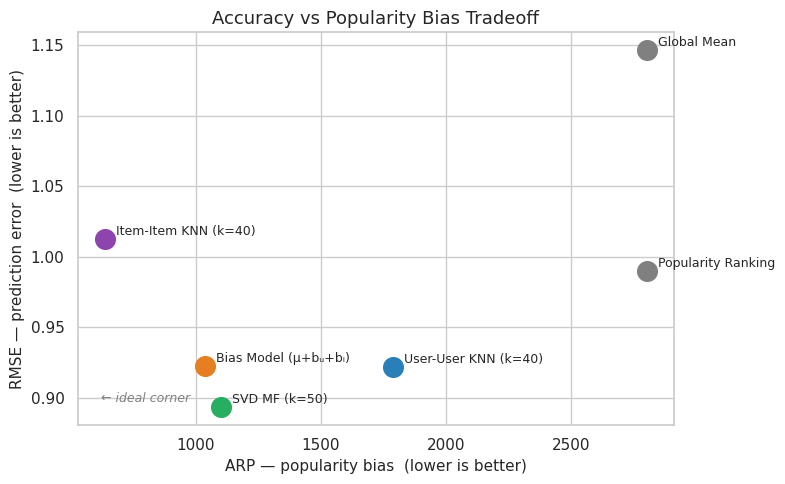

In [28]:
# Plot 3: Accuracy vs Bias tradeoff
res_sc = res_df.dropna(subset=['rmse']).copy()

color_map = {
    'Bias Model (μ+bᵤ+bᵢ)':      '#e67e22',
    f'User-User KNN (k={K_USERS})': '#2980b9',
    f'Item-Item KNN (k={K_ITEMS})': '#8e44ad',
    f'SVD MF (k={N_FACTORS})':      '#27ae60',
}

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in res_sc.iterrows():
    c = color_map.get(row['model'], 'grey')
    ax.scatter(row['arp'], row['rmse'], s=200, color=c, zorder=5)
    ax.annotate(row['model'], (row['arp'], row['rmse']),
                textcoords='offset points', xytext=(8, 3), fontsize=9)

ax.set_xlabel('ARP — popularity bias  (lower is better)', fontsize=11)
ax.set_ylabel('RMSE — prediction error  (lower is better)', fontsize=11)
ax.set_title('Accuracy vs Popularity Bias Tradeoff', fontsize=13)
ax.annotate('← ideal corner', xy=(0.04, 0.06), xycoords='axes fraction',
            color='grey', style='italic', fontsize=9)
plt.tight_layout()
plt.savefig('tradeoff.png', dpi=150)
plt.show()

---
## Baseline Selection — Decision & Justification

### Why not pick Item-Item KNN (lowest ARP)?

Item-Item KNN already achieves ARP=98.8 and 87.6% coverage — but this is a **side effect** of item-item similarity geometry, not a designed debiasing mechanism. Picking it as baseline creates two problems:
- Almost no headroom to show improvement on bias
- Accuracy is noticeably worse (RMSE=0.98 vs 0.94) — a debiased system built on top would inherit this penalty

### Why not User-User KNN?

User-User KNN has good accuracy (RMSE=0.94) but its ARP of 280.6 is actually *higher* than SVD (205.7) and the Bias Model (212.8). It is more biased than simpler methods, which makes it a poor foundation — we'd be starting from a worse position than necessary.

### Our choice: **SVD (Matrix Factorization, k=50)**

| Criterion | Justification |
|---|---|
| **Best accuracy** | Lowest RMSE (0.9357) — strongest benchmark to beat, makes our results credible |
| **Clear measurable bias** | ARP=205.7, Coverage=10.8% — significantly biased despite good accuracy |
| **Bias is explainable** | Popular items have far more training examples → their latent vectors q_i are better optimised → they systematically rank higher in dot-product scoring |
| **Natural fit for debiasing** | Debiasing techniques (IPS reweighting, popularity-penalised regularisation, exposure modelling) all integrate directly into the MF training objective |
| **Well-established** | SVD/MF is the dominant paradigm in CF literature post-Netflix Prize |
| **Meaningful headroom** | ARP of 205.7 leaves clear room to improve toward Item-Item KNN's 98.8, while targeting better RMSE than Item-Item KNN's 0.98 |

**The target we are setting for our debiased system:**
> Beat SVD on *both* dimensions — lower ARP than SVD (205.7) while maintaining RMSE competitive with SVD (0.9357).  
> Item-Item KNN shows that low ARP *is achievable* at 98.8 — our system should approach that without sacrificing accuracy.

**Item-Item KNN** becomes our bias *reference point* — proof that low ARP is achievable.  
**User-User KNN and Bias Model** become additional comparison points in final evaluation.

**Project narrative:**
> *SVD is the most accurate standard CF algorithm, yet it still exhibits strong popularity bias — ARP of 205.7 with only 10.8% catalogue coverage. This accuracy-bias gap is exactly the problem our system targets: achieving SVD-level accuracy while dramatically reducing its popularity bias.*

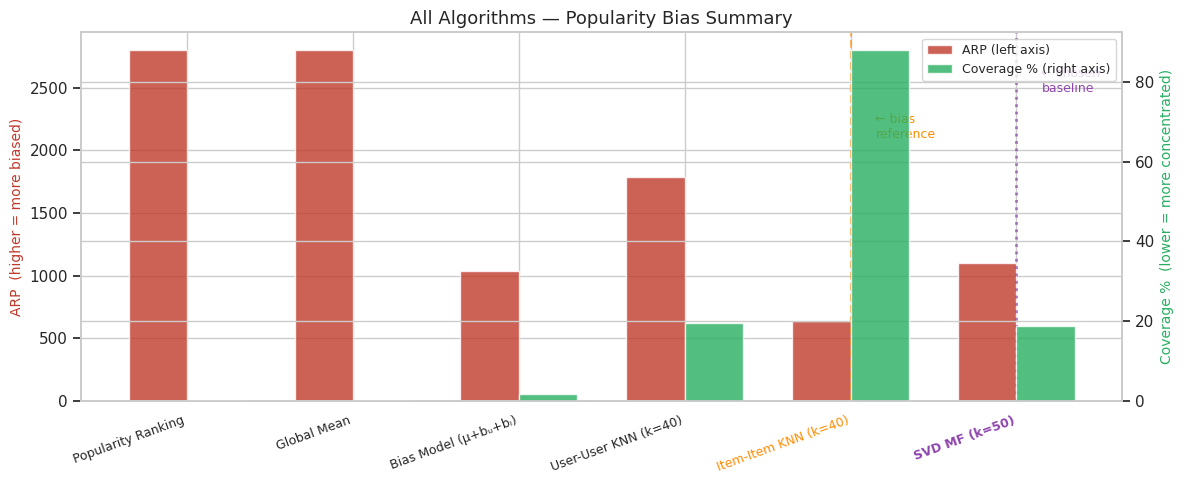


✓ Baseline selected  : SVD MF (k=50, SGD, factors trained on observed ratings)
  Bias reference     : Item-Item KNN (ARP=98.8) — proves low ARP is achievable
  Target             : Match SVD accuracy (RMSE~0.94) with ARP closer to Item-Item KNN
  Next step          : Build debiased MF system on top of this baseline.


In [29]:
# Final summary plot
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(res_df))
w = 0.35

b1 = ax.bar(x - w/2, res_df['arp'],             color='#c0392b', alpha=0.8, width=w, label='ARP (left axis)')
ax2 = ax.twinx()
b2 = ax2.bar(x + w/2, res_df['coverage'] * 100, color='#27ae60', alpha=0.8, width=w, label='Coverage % (right axis)')

ax.set_xticks(x)
ax.set_xticklabels(res_df['model'], rotation=20, ha='right', fontsize=9)
ax.set_ylabel('ARP  (higher = more biased)', color='#c0392b', fontsize=10)
ax2.set_ylabel('Coverage %  (lower = more concentrated)', color='#27ae60', fontsize=10)
ax.set_title('All Algorithms — Popularity Bias Summary', fontsize=13)

# Annotate chosen baseline (SVD)
baseline = f'SVD MF (k={N_FACTORS})'
if baseline in res_df['model'].values:
    b_idx = res_df['model'].tolist().index(baseline)
    ax.get_xticklabels()[b_idx].set_fontweight('bold')
    ax.get_xticklabels()[b_idx].set_color('#8e44ad')
    ax.axvline(b_idx, color='#8e44ad', linestyle=':', linewidth=2, alpha=0.7)
    ax.text(b_idx + 0.15, max(res_df['arp']) * 0.88,
            '← chosen\nbaseline', color='#8e44ad', fontsize=9)

# Annotate Item-Item KNN as bias reference point
ref = f'Item-Item KNN (k={K_ITEMS})'
if ref in res_df['model'].values:
    r_idx = res_df['model'].tolist().index(ref)
    ax.get_xticklabels()[r_idx].set_color('darkorange')
    ax.axvline(r_idx, color='darkorange', linestyle='--', linewidth=1.5, alpha=0.6)
    ax.text(r_idx + 0.15, max(res_df['arp']) * 0.75,
            '← bias\nreference', color='darkorange', fontsize=9)

ax.legend(handles=[b1, b2], loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('final_summary.png', dpi=150)
plt.show()

print('\n✓ Baseline selected  : SVD MF (k=50, SGD, factors trained on observed ratings)')
print('  Bias reference     : Item-Item KNN (ARP=98.8) — proves low ARP is achievable')
print('  Target             : Match SVD accuracy (RMSE~0.94) with ARP closer to Item-Item KNN')
print('  Next step          : Build debiased MF system on top of this baseline.')